In [133]:
import pandas as pd

column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
data = pd.read_csv('housing.csv', header=None, delimiter=r"\s+", names=column_names)
data.head(5)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [157]:
x = data.iloc[:,0:13]
y = data.iloc[:,13]

In [158]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [159]:
from sklearn.tree import DecisionTreeRegressor

regTree = DecisionTreeRegressor()
regTree.fit(x_train,y_train)

DecisionTreeRegressor()

In [160]:
y_pred = regTree.predict(x_test)

In [161]:
from sklearn.metrics import r2_score

r2_score(y_test,y_pred)

0.6898481591572496

# hyperparameter tuning

In [139]:

param_grid = {
    'max_depth':[1,2,3,4,5,6,7,8,9,10,None],
    'criterion':['squared_error','absolute_error','poisson'],
    'splitter' : ['best','random'],
    'max_features':[0.25,0.5,1.0]
}

In [140]:
from sklearn.model_selection import GridSearchCV

reg = GridSearchCV(DecisionTreeRegressor(),param_grid = param_grid)
reg.fit(x_train,y_train)

GridSearchCV(estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'absolute_error',
                                       'poisson'],
                         'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, None],
                         'max_features': [0.25, 0.5, 1.0],
                         'splitter': ['best', 'random']})

In [141]:
print(reg.best_estimator_)

DecisionTreeRegressor(criterion='poisson', max_features=0.5)


In [142]:
reg.best_score_

np.float64(0.7638794074301566)

In [143]:
reg.best_params_

{'criterion': 'poisson',
 'max_depth': None,
 'max_features': 0.5,
 'splitter': 'best'}

# feature importance

In [144]:
x_list = []
y_list = []
for importance,name in sorted(zip(regTree.feature_importances_,x_train.columns)):
  print(name,importance)
  x_list.append(name)
  y_list.append(importance)

CHAS 3.887077764906582e-16
RAD 0.0022594461362891345
ZN 0.0028370160039196514
INDUS 0.005497917705974196
NOX 0.007448949543667647
B 0.010353007404449914
TAX 0.011608256166528408
AGE 0.014978497896408533
PTRATIO 0.026916858755125447
CRIM 0.05107687390060415
DIS 0.06637046827214893
LSTAT 0.2114376383135083
RM 0.5892150699013754


<BarContainer object of 13 artists>

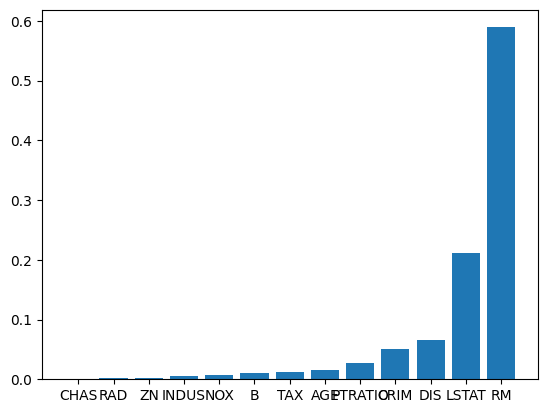

In [145]:
import matplotlib.pyplot as plt

plt.bar(x_list,y_list)

housing prices are majorly dependent on RM : average number of rooms per dwelling

# Tree visualization for regression

In [93]:
!pip install dtreeviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 3.5 MB/s eta 0:00:00


In [154]:
rt = DecisionTreeRegressor(max_depth = 3)
rt.fit(x_train,y_train)

DecisionTreeRegressor(max_depth=3)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


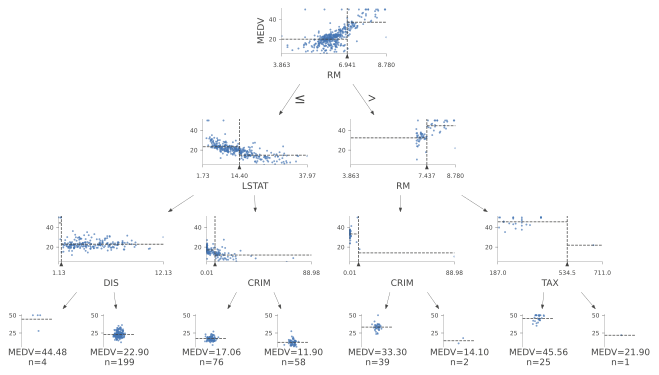

In [155]:
import dtreeviz
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']

features = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

viz_model = dtreeviz.model(
    rt,
    X_train=x_train,
    y_train=y_train,
    target_name='MEDV',
    feature_names=features,
)

viz_model.view(fontname='sans-serif')

visualization of how regression tree with multiple features is split ( max_depth = 3 )

/usr/local/lib/python3.13/dist-packages/dtreeviz/models/shadow_decision_tree.py:335: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
/usr/local/lib/python3.13/dist-packages/dtreeviz/trees.py:748: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
/usr/local/lib/python3.13/dist-packages/dtreeviz/trees.py:1778: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`


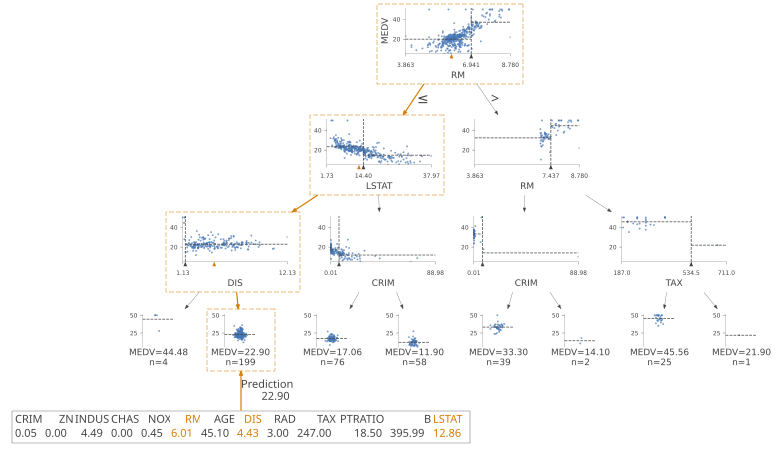

In [162]:
value = x_test.iloc[100]

viz_model.view(x=value, fontname='sans-serif')

closely accurate prediction <br>
predicted : 22.9 <br>
real : 22.5

In [163]:
print(y_test.iloc[100])

22.5


# tree visualization for classification

In [164]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris

iris = load_iris()
y_train = iris.target
x_train = iris.data

clf = DecisionTreeClassifier()
clf.fit(x_train,y_train)

DecisionTreeClassifier()

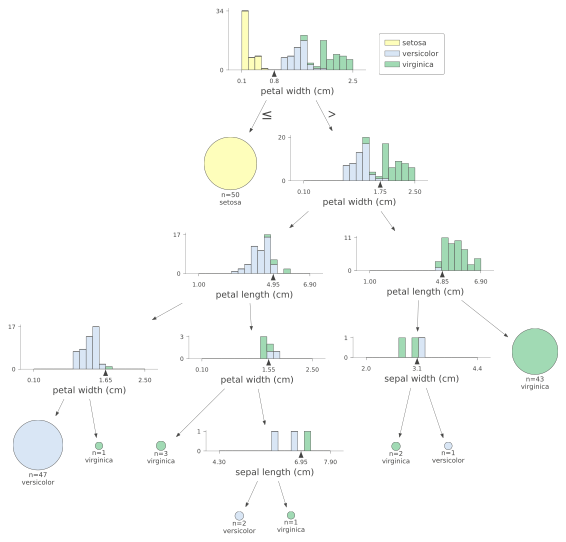

In [167]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial']

viz_model = dtreeviz.model(
    clf,
    x_train,
    y_train,
    feature_names=iris.feature_names,
    class_names=["setosa", "versicolor", "virginica"]
)

# You need to call .view() to generate and display the visualization
viz_model.view(fontname='sans-serif')

visualization of how decision tree classifier splits data for iris dataset

Prediction Path Text Explanation:
4.85 <= petal length (cm) 
1.75 <= petal width (cm) 



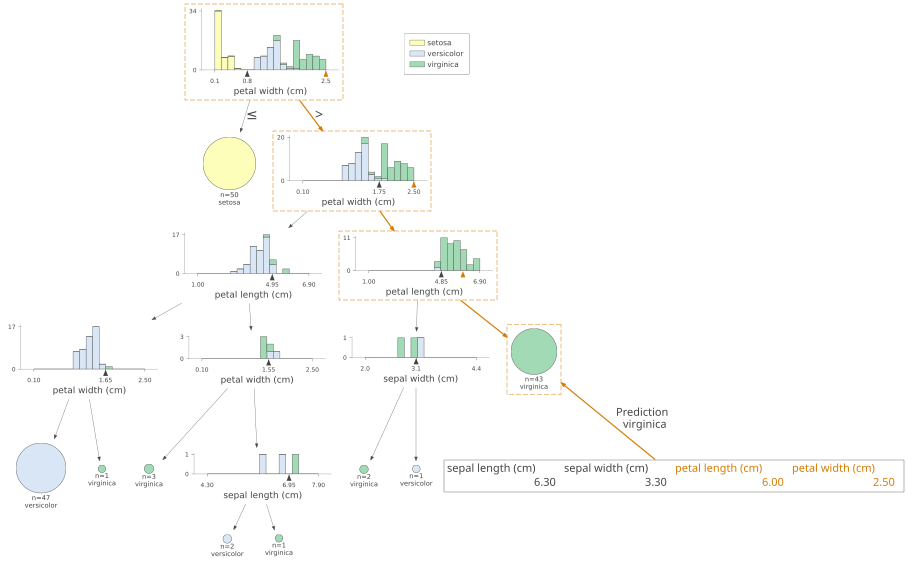

In [169]:

value = x_train[100]

text_explanation = viz_model.explain_prediction_path(value)
print("Prediction Path Text Explanation:")
print(text_explanation)

viz_model.view(x=value, fontname='sans-serif')

prediction path

In [170]:
print(y_train[100])

2


accurate prediction